In [ ]:
import cv2
import matplotlib.pyplot as plt
import sys
from pathlib import Path
#bắt nó về root
ROOT_DIR = Path(r"H:\FPT\4\CPV\project\CPV301")

sys.path.insert(0, str(ROOT_DIR))

from src.path import RAW_DATA_DIR, OUTPUT_DATA_DIR

Đường dẫn: H:\FPT\4\CPV\project\CPV301\data\raw\20.jpg
Kích thước: 1280 x 720 pixels


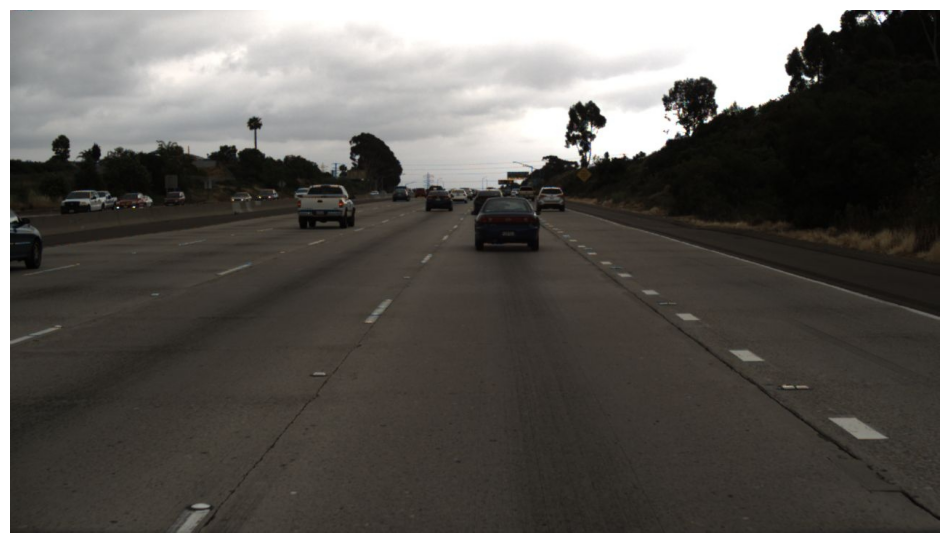

In [ ]:
# Lấy danh sách file ảnh trong RAW_DATA_DIR
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_files = [
    p for p in Path(RAW_DATA_DIR).rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

if not image_files:
    print(f"Không tìm thấy ảnh trong: {RAW_DATA_DIR}")
else:
    image_path = image_files[0]
    image = cv2.imread(str(image_path))

    if image is None:
        print(f"Không thể đọc ảnh: {image_path}")
    else:
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        print(f"Đường dẫn: {image_path}")
        print(f"Kích thước: {image.shape[1]} x {image.shape[0]} pixels")

        plt.figure(figsize=(12, 7))
        plt.imshow(image_rgb)
        plt.axis("off")
        plt.show()

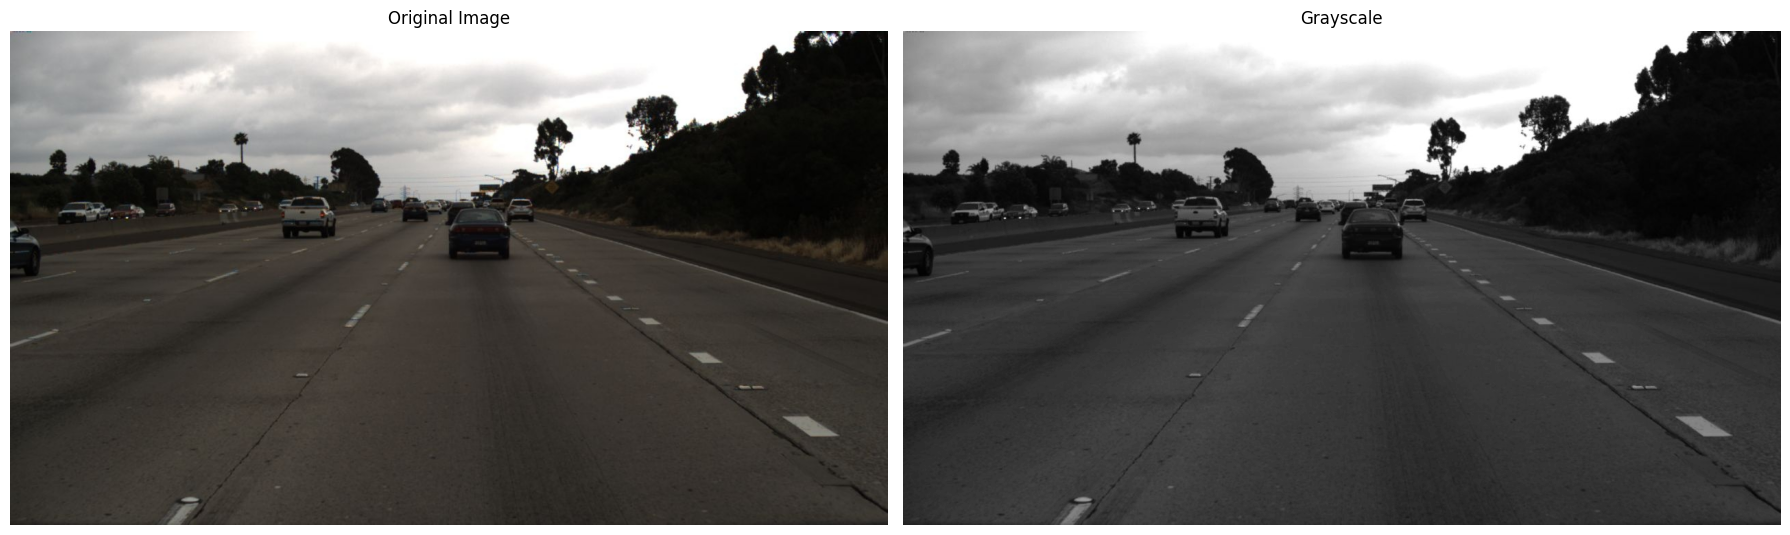

In [ ]:
# 1. Chuyển ảnh sang thang độ xám
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


# 3. So sánh kết quả
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Image")

axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Grayscale")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


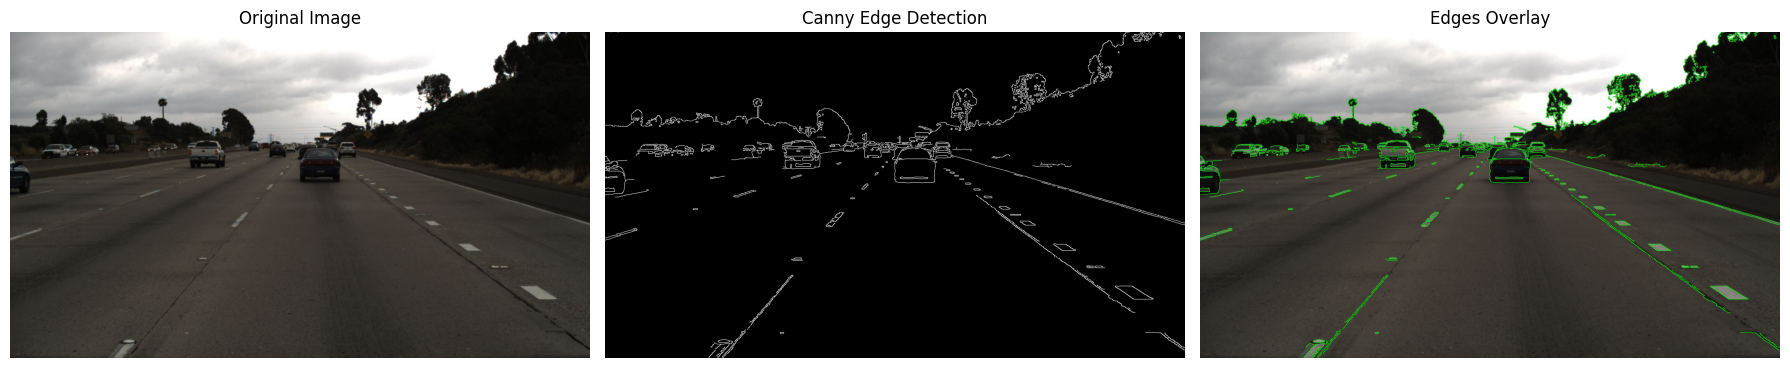

In [ ]:
# 1. Phát hiện biên trên ảnh xám
edges = cv2.Canny(gray, threshold1=50, threshold2=150)

# 2. Vẽ các đường biên lên ảnh gốc
edge_overlay = image.copy()
edge_overlay[edges > 0] = [0, 255, 0]  # Biên màu xanh lá (BGR)

# 3. Hiển thị kết quả
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Image")

axes[1].imshow(edges, cmap="gray")
axes[1].set_title("Canny Edge Detection")

axes[2].imshow(cv2.cvtColor(edge_overlay, cv2.COLOR_BGR2RGB))
axes[2].set_title("Edges Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


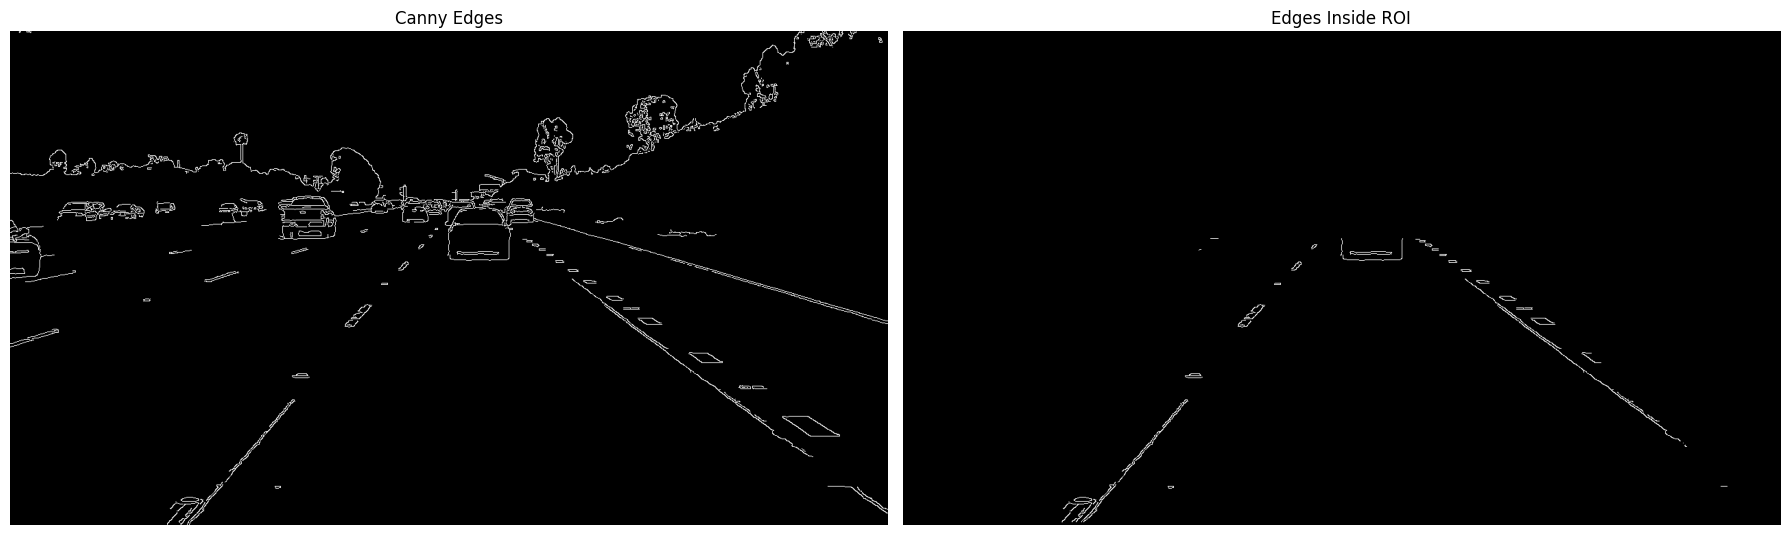

In [ ]:
import numpy as np
# Kích thước ảnh
height, width = edges.shape[:2]

# Khung ROI theo hình bạn đánh dấu
roi_vertices = np.array([[
    (int(width * 0.02), height - 5),       # Góc dưới trái
    (int(width * 0.35), int(height * 0.42)), # Góc trên trái
    (int(width * 0.65), int(height * 0.42)), # Góc trên phải
    (int(width * 0.98), height - 5)        # Góc dưới phải
]], dtype=np.int32)

# Tạo mask: vùng bên trong khung là trắng, bên ngoài là đen
mask = np.zeros_like(edges)
cv2.fillPoly(mask, roi_vertices, 255)

# Chỉ giữ các cạnh nằm trong ROI
roi_edges = cv2.bitwise_and(edges, mask)

# Hiển thị kết quả
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].imshow(edges, cmap="gray")
axes[0].set_title("Canny Edges")

axes[1].imshow(roi_edges, cmap="gray")
axes[1].set_title("Edges Inside ROI")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

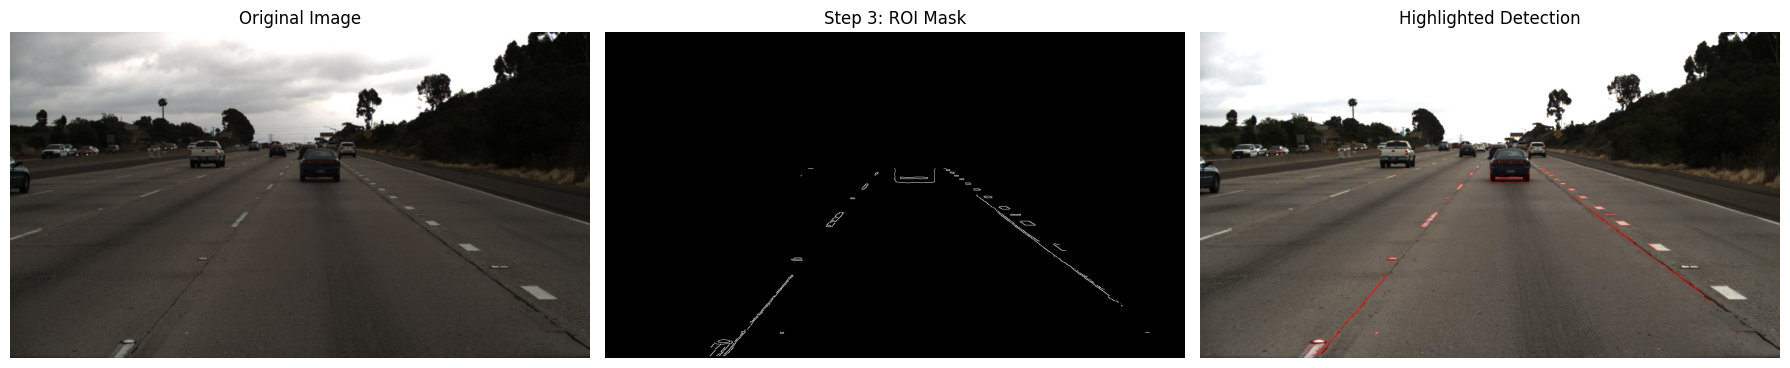

In [ ]:
# Ảnh gốc và mask phải có cùng kích thước
# roi_edges là kết quả bước 3 của bạn
assert image.shape[:2] == roi_edges.shape[:2], \
    "Kích thước ảnh gốc và ROI mask không khớp"

# Chỉ lấy vị trí các pixel đã được giữ lại ở bước 3
detected_mask = roi_edges > 0

# Tạo ảnh làm nổi bật các vị trí phát hiện
highlighted = image.copy()

# Tô vàng lên vị trí phát hiện để dễ kiểm tra
highlighted[detected_mask] = (0, 0, 255)  # BGR

# Trộn nhẹ với ảnh gốc để vẫn nhìn thấy cảnh vật
result = cv2.addWeighted(image, 0.65, highlighted, 0.9, 0)

# Hiển thị ảnh gốc, mask và ảnh đối chiếu
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Image")

axes[1].imshow(roi_edges, cmap="gray")
axes[1].set_title("Step 3: ROI Mask")

axes[2].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
axes[2].set_title("Highlighted Detection")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

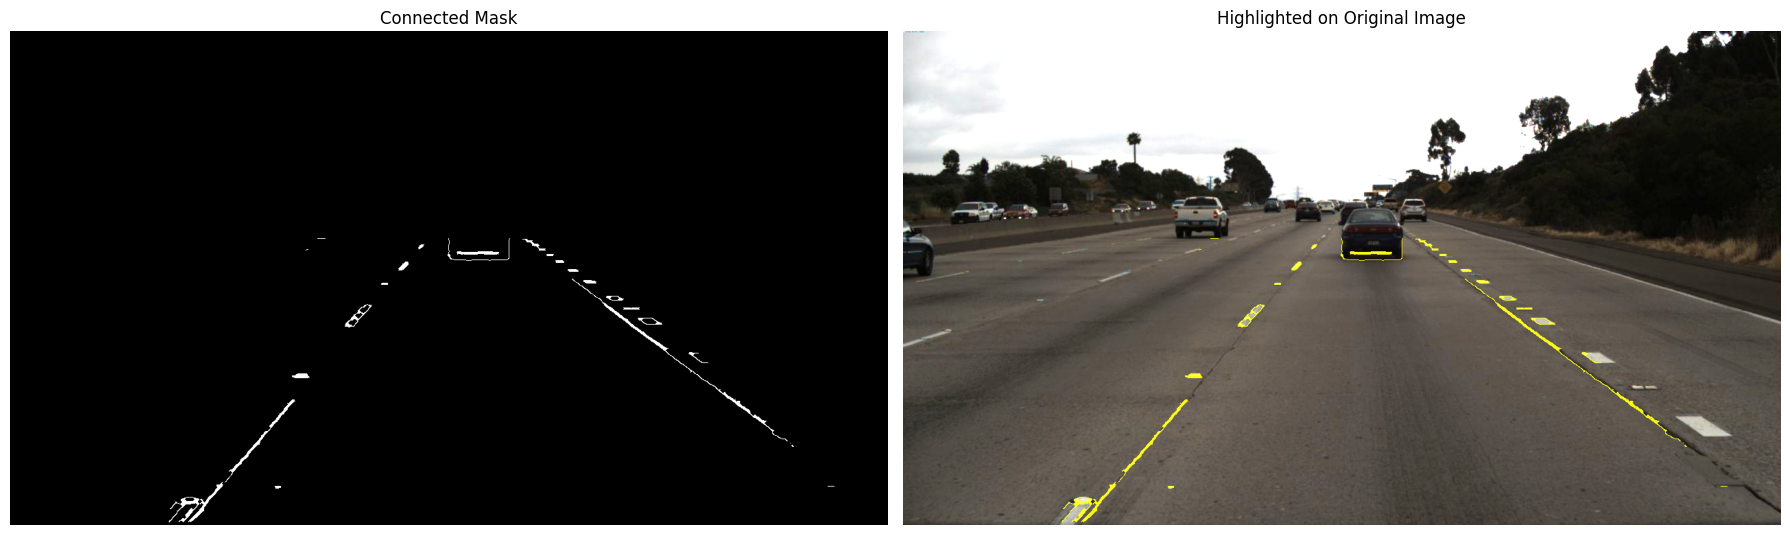

In [ ]:
# 1. Tạo mask nhị phân từ kết quả ROI
lane_mask = (roi_edges > 0).astype(np.uint8) * 255

# 2. Nối các đoạn cạnh gần nhau bằng morphological closing
# Kernel nhỏ để hạn chế nối nhầm các vật thể khác
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
connected_mask = cv2.morphologyEx(
    lane_mask,
    cv2.MORPH_CLOSE,
    kernel,
    iterations=2
)

# 3. Làm nổi bật các vị trí đã nối trên ảnh gốc
highlighted = image.copy()
highlighted[connected_mask > 0] = (0, 255, 255)  # Vàng

result = cv2.addWeighted(image, 0.65, highlighted, 0.9, 0)

# 4. Hiển thị kết quả
fig, axes = plt.subplots(1, 2, figsize=(18, 6))


axes[0].imshow(connected_mask, cmap="gray")
axes[0].set_title("Connected Mask")

axes[1].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
axes[1].set_title("Highlighted on Original Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()
